<a href="https://colab.research.google.com/github/nikaivanisova/projekty/blob/main/ANO_zadanie1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [66]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

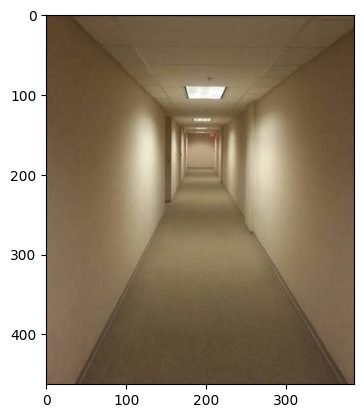

In [67]:
# nacitanie a vykreslenie obrazku a prevod z BGR do RGB
img = cv.imread("/content/drive/MyDrive/UPJS/3.roc/ZS/ANO/images (3).jpg")
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
plt.imshow(img_rgb)

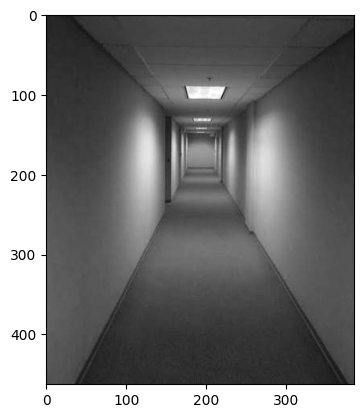

In [68]:
# prevod na sedotonovy obrazok
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
plt.imshow(img_gray, cmap='gray')

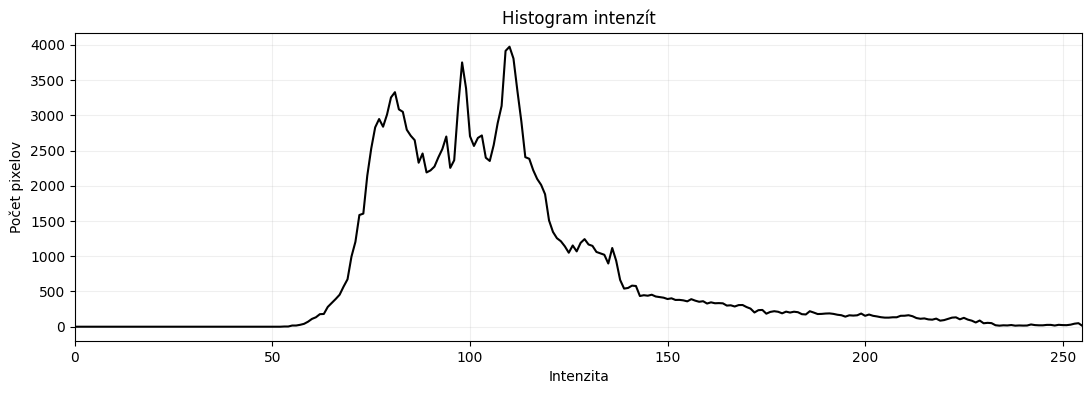

In [69]:
# vykreslenie histogramu
hist = cv.calcHist([img_gray], [0], None, [256], [0, 256]).ravel()
plt.figure(figsize=(13, 4))
plt.plot(np.arange(256), hist, color="black")
plt.title
plt.xlabel("Intenzita")
plt.ylabel("Počet pixelov")
plt.title("Histogram intenzít")
plt.xlim(0, 255)
plt.grid(alpha=0.2)
plt.show()

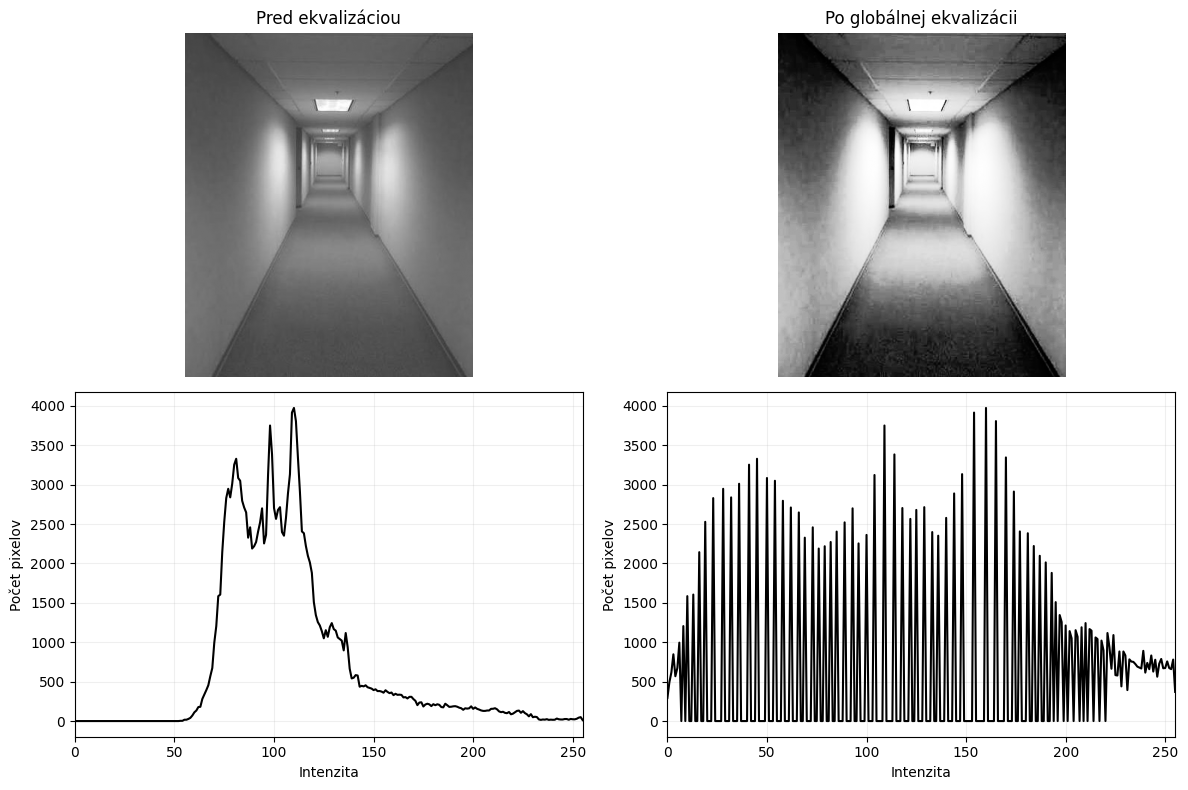

In [70]:
# ekvalizacia histogramu
equalized = cv.equalizeHist(img_gray)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, (image, title) in enumerate([
    (img_gray, "Pred ekvalizáciou"),
    (equalized, "Po globálnej ekvalizácii"),
]):
    axes[0, column].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0, column].set_title(title)
    axes[0, column].axis("off")
    hist = cv.calcHist([image], [0], None, [256], [0, 256])
    axes[1, column].plot(hist, color="black")
    axes[1, column].set_xlim(0, 255)
    axes[1, column].set_xlabel("Intenzita")
    axes[1, column].set_ylabel("Počet pixelov")
    axes[1, column].grid(alpha=0.2)
plt.tight_layout()
plt.show()

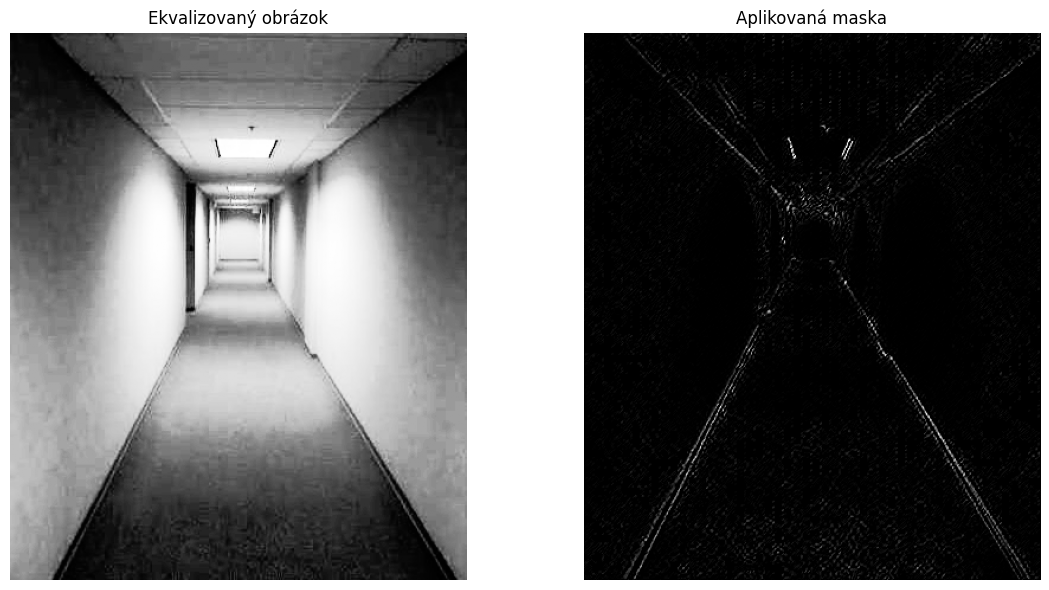

In [71]:
# aplikovanie 45° masky
kernel = np.array([[-1, -1, 2], [-1, 2, -1], [2, -1, -1]], dtype=np.float32)
filtered_img = cv.filter2D(equalized, -1, kernel)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(equalized, cmap='gray')
axes[0].set_title('Ekvalizovaný obrázok')
axes[0].axis('off')

axes[1].imshow(filtered_img, cmap='gray')
axes[1].set_title('Aplikovaná maska')
axes[1].axis('off')

plt.tight_layout()
plt.show()

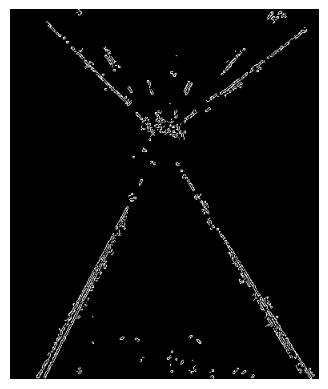

In [72]:
# aplikacia Canny hranoveho detektora
edges = cv.Canny(filtered_img, 100, 300)
plt.axis('off')
plt.imshow(edges, cmap='gray')

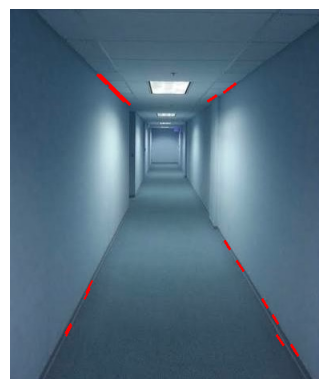

In [73]:
# HoughLinesP použité na identifikáciu čiar
minLineLength = 50
maxLineGap = 10
lines = cv.HoughLinesP(edges, 1, np.pi/180, 50, minLineLength, maxLineGap)

for x1, y1, x2, y2 in lines:
    cv.line(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
plt.axis('off')
plt.imshow(img, cmap='gray')


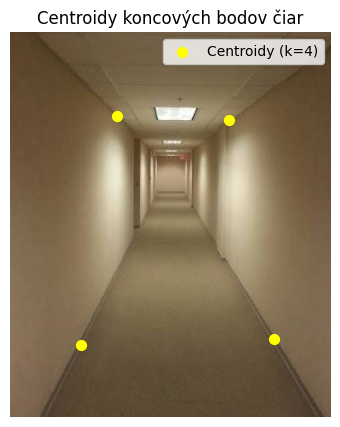

In [74]:
from sklearn.cluster import KMeans
#extrakcia koncovych bodov najdenych ciar
endpoints = []
for x1, y1, x2, y2 in lines:
    endpoints.append([x1, y1])
    endpoints.append([x2, y2])

endpoints = np.array(endpoints)

#K-means pre k = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
k_predictions = kmeans.fit(endpoints)
centroids = kmeans.cluster_centers_

#vykreslenie povodneho obrázka s centroidmi
plt.figure(figsize=(8, 5))
plt.imshow(img_rgb)
plt.scatter(centroids[:, 0], centroids[:, 1], color='yellow', s=50, label='Centroidy (k=4)', zorder=5)

plt.title('Centroidy koncových bodov čiar')
plt.legend()
plt.axis('off')
plt.show()


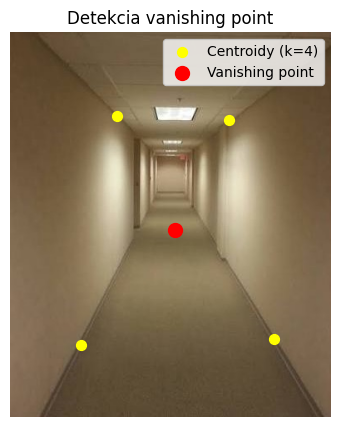

In [76]:
# K-means pre k=1
kmeans_vp = KMeans(n_clusters=1, random_state=42, n_init=10)
kmeans_vp.fit(centroids)
vanishing_point = kmeans_vp.cluster_centers_[0]

# vykreslenie obrazka s centroidmi a koncovym bodom
plt.figure(figsize=(8, 5))
plt.imshow(img_rgb)
plt.scatter(centroids[:, 0], centroids[:, 1], color='yellow', s=50, label='Centroidy (k=4)')
plt.scatter(vanishing_point[0], vanishing_point[1], color='red', s=100, label='Vanishing point')

plt.title('Detekcia vanishing point')
plt.legend()
plt.axis('off')
plt.show()

AI som použila na naprogramovanie K-means a na pripomenutie si, čo robia parametre niektorých funkcií. Po dlhom nastavovaní parametrov a nedosiahnutí priaznivého výsledku (správneho určenia vanishing point) som sa AI pýtala, či sú aspoň čiastkové výsledky, napr. po Canny hranovej detekcii, približne dobré, čo mi bolo potvrdené.